# dc-forecast-control on Kaggle

Runs all steps of the experiment: data, forecasters, decision module, hall simulator, stats and figures.

Settings: Accelerator = GPU T4, Internet = On.

Data: either attach a Kaggle dataset with `services.npz` (key `g20`, 199 halls × 8784 min, made by step 1),
or attach nothing and the notebook will download the Alibaba trace (1.7 GB) and build it (+25 min).

Save & Run All takes about 1.5 h. Results are in the Output tab: `results_dc_forecast_control.zip`.

In [1]:
# settings
SEEDS = "0,1,2,3,4,5,6,7,8,9"                # 10 training runs per GRU variant
HORIZONS = {5: SEEDS, 10: SEEDS, 15: SEEDS}   # minutes ahead
QUICK_TEST = False   # True = 20 halls, 1 seed, 2 epochs, just to see that everything runs

import os, subprocess, time
WORK = "/kaggle/working/dc_forecast_control"
for d in ("dccontrol", "scripts", "data", "results"):
    os.makedirs(f"{WORK}/{d}", exist_ok=True)
os.chdir(WORK)
T0 = time.time()

def run(cmd):
    # run a command, print its output, stop if it fails
    print(f"\n$ {cmd}   [{(time.time() - T0) / 60:.0f} min]", flush=True)
    p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        print(line, end="", flush=True)
    if p.wait() != 0:
        raise RuntimeError(cmd)

run("pip -q install numba")
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU, turn it on in settings")


$ pip -q install numba   [0 min]
GPU: Tesla T4


## Code
These cells just save the package and scripts to disk (same files as in the repo).

In [2]:
%%writefile dccontrol/__init__.py
"""Forecast-based control of servers and cooling in a small two-zone data hall.

data.py       - read the Alibaba 2018 trace, make per-minute load of each hall
forecast.py   - persistence, ridge and GRU forecasters, asymmetric loss
hall.py       - decision module + hall simulator
calibrate.py  - pick the server reserve m and the temperature setback s
"""

Writing dccontrol/__init__.py


In [3]:
%%writefile dccontrol/data.py
"""Load data from the Alibaba cluster trace v2018 (https://github.com/alibaba/clusterdata).

machine_usage.csv has no header, columns are:
    machine_id, time_stamp (s), cpu_util_percent, mem_util_percent, mem_gps, mkpi,
    net_in, net_out, disk_io_percent
It's about 4000 machines over 8 days, 1.7 GB zipped. We read it straight from the .tar.gz,
so there's no need to unpack 270M rows to disk.

Hall load = sum of cpu% of its machines / 100, i.e. how many fully busy servers it needs.
One group of 20 machines = one small hall.
"""
from __future__ import annotations

import subprocess

import numpy as np
import pandas as pd

TRACE_URL = "http://aliopentrace.oss-cn-beijing.aliyuncs.com/v2018Traces/machine_usage.tar.gz"
MINUTES = 8 * 1440          # 8 days


def load_machine_minutes(tar_path: str, chunksize: int = 5_000_000, max_minutes: int = MINUTES,
                         log=print) -> tuple[np.ndarray, list[str]]:
    """Mean cpu% of each machine in each minute.

    Returns a [machines x minutes] matrix (NaN if a machine sent nothing that minute) and machine ids.
    Samples come every 10-60 s, so one cell = mean of the samples inside that minute.
    """
    index = pd.Index([], dtype=object)
    sums = np.zeros((4200, max_minutes), np.float64)     # sum of cpu% per cell
    cnts = np.zeros((4200, max_minutes), np.float32)     # how many samples per cell
    rows = 0
    # tar prints the csv to stdout and pandas reads it in chunks
    proc = subprocess.Popen(["tar", "-xzOf", tar_path], stdout=subprocess.PIPE)
    for ch in pd.read_csv(proc.stdout, header=None, usecols=[0, 1, 2], names=["m", "t", "cpu"],
                          chunksize=chunksize, dtype={"m": str, "t": float, "cpu": float}):
        ch = ch[(ch.cpu >= 0) & (ch.cpu <= 100) & (ch.t >= 0)]          # skip broken rows
        ch = ch.assign(mi=(ch.t // 60).astype(np.int64))                  # seconds -> minute
        ch = ch[ch.mi < max_minutes]
        new_ids = pd.Index(ch.m.unique()).difference(index)
        if len(new_ids):                                                  # more machines than rows -> add rows
            index = index.append(new_ids)
            while len(index) > sums.shape[0]:
                sums = np.vstack([sums, np.zeros((500, max_minutes))])
                cnts = np.vstack([cnts, np.zeros((500, max_minutes), np.float32)])
        ch = ch.assign(code=index.get_indexer(ch.m))
        agg = ch.groupby(["code", "mi"]).cpu.agg(["sum", "count"]).reset_index()
        np.add.at(sums, (agg.code.to_numpy(), agg.mi.to_numpy()), agg["sum"].to_numpy())
        np.add.at(cnts, (agg.code.to_numpy(), agg.mi.to_numpy()), agg["count"].to_numpy())
        rows += len(ch)
        log(f"  {rows / 1e6:.0f}M rows read, {len(index)} machines so far")
    proc.wait()
    n = len(index)
    with np.errstate(invalid="ignore", divide="ignore"):
        cpu = (sums[:n] / cnts[:n]).astype(np.float32)
    return cpu, list(index)


def clean_machines(cpu: np.ndarray, max_missing: float = 0.05, min_machines: int = 400, log=print) -> np.ndarray:
    """Remove gaps.

    1) keep the longest stretch of minutes where at least half of the machines have data
       (start and end of the trace are almost empty)
    2) drop machines that miss more than max_missing of those minutes
    3) fill what's left with the previous value of the same machine
    """
    have = ~np.isnan(cpu)
    good = have.mean(0) >= 0.5
    best, start = (0, 0, 0), None
    for t, ok in enumerate(np.append(good, False)):
        if ok and start is None:
            start = t
        if not ok and start is not None:
            if t - start > best[0]:
                best = (t - start, start, t)
            start = None
    _, t0, t1 = best
    log(f"using minutes {t0}..{t1} ({(t1 - t0) / 1440:.2f} days)")
    x = cpu[:, t0:t1]
    miss = np.isnan(x).mean(1)
    thr = max_missing
    while (miss <= thr).sum() < min_machines and thr < 0.5:   # only if too few machines are left
        thr += 0.05
    ok = miss <= thr
    x = pd.DataFrame(x[ok].T).ffill().bfill().to_numpy().T
    log(f"kept {ok.sum()} of {len(cpu)} machines (missing <= {thr:.2f})")
    return x.astype(np.float32)


def make_groups(cpu: np.ndarray, group: int, seed: int = 0) -> np.ndarray:
    """Shuffle machines, cut them into groups of `group` and return the load of each group
    in busy servers (sum of cpu% / 100)."""
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(cpu))
    n = len(idx) // group
    return np.stack([cpu[idx[i * group:(i + 1) * group]].sum(0) / 100.0 for i in range(n)]).astype(np.float32)


def synthetic_machines(n: int = 400, minutes: int = MINUTES, seed: int = 0) -> np.ndarray:
    """Fake machines (flat, daily cycle, bursts). Just to test that the code runs."""
    rng = np.random.default_rng(seed)
    t = np.arange(minutes)
    out = np.empty((n, minutes), np.float32)
    for i in range(n):
        x = rng.uniform(15, 45) + rng.normal(0, 1.5, minutes)
        if i % 3 >= 1:
            x += rng.uniform(5, 20) * np.sin(2 * np.pi * (t / 1440 - rng.uniform()))
        if i % 3 == 2:
            for s in rng.integers(0, minutes - 60, size=rng.integers(20, 80)):
                x[s:s + rng.integers(3, 40)] += rng.uniform(15, 45)
        out[i] = np.clip(x, 0, 100)
    return out

Writing dccontrol/data.py


In [4]:
%%writefile dccontrol/forecast.py
"""Forecasters: load of the hall H minutes ahead.

Every model gets the last 60 minutes of load (up to minute t - H) and predicts the load at minute t.

- persistence: just repeats d[t - H]
- ridge: linear regression on the 60 values with L2 penalty
- GRU: small recurrent net (Cho et al., 2014), 64 hidden units

Ridge and GRU predict the change z[t] - z[t - H] of the normalised load, and we add it to the
last known value. This way one model works for halls with very different load levels.

GRU is trained with MSE or with the asymmetric loss

    L = mean( lam * max(d - y, 0) + max(y - d, 0) )

d - real load, y - forecast. Underestimating costs lam times more than overestimating.
lam = 1 is plain MAE. The minimum of this loss is the quantile tau = lam / (1 + lam)
(Koenker & Bassett, 1978), e.g. for lam = 8 the load goes above the forecast in ~1 of 9 minutes.
"""
from __future__ import annotations

import numpy as np
import torch
import torch.nn as nn

L = 60      # history length, minutes


# ---- windows
def make_windows(S, mu, sd, H, t_from, t_to, stride=1):
    """Cut the series into (input, target) pairs.

    S - load [series x minutes], mu/sd - mean and std of the training part of each series,
    t_from..t_to - which target minutes to use. Input is z[t-H-L+1 .. t-H].
    Returns X [n, L], y [n] (change z[t] - z[t-H]), series index, target minute.
    """
    Xs, ys, ids, ts = [], [], [], []
    for i, x in enumerate(S):
        z = (x - mu[i]) / sd[i]
        t = np.arange(max(t_from, L + H - 1), t_to, stride)
        if len(t) == 0:
            continue
        idx = (t - H)[:, None] - np.arange(L - 1, -1, -1)[None, :]
        Xs.append(z[idx].astype(np.float32))
        ys.append((z[t] - z[t - H]).astype(np.float32))
        ids.append(np.full(len(t), i))
        ts.append(t)
    return np.concatenate(Xs), np.concatenate(ys), np.concatenate(ids), np.concatenate(ts)


def to_level(S, mu, sd, ids, t, dz, H):
    """Predicted change -> load in busy servers."""
    yhat = np.full(S.shape, np.nan)
    z_last = (S[ids, t - H] - mu[ids]) / sd[ids]
    yhat[ids, t] = (z_last + dz) * sd[ids] + mu[ids]
    return yhat


def persistence(S, H):
    """Forecast for t = load at t - H."""
    return np.c_[np.full((S.shape[0], H), np.nan), S[:, :-H]]


# ---- ridge
def ridge(Xtr, ytr, Xva, yva, alphas=(0.1, 1, 10, 100, 1000)):
    """Ridge regression on 60 lags + intercept.

    Neighbouring minutes are almost the same, so plain least squares gives huge weights with
    opposite signs. The penalty keeps them small. alpha is picked by MAE on validation.
    """
    A = np.c_[Xtr, np.ones(len(Xtr))].astype(np.float64)
    Av = np.c_[Xva, np.ones(len(Xva))].astype(np.float64)
    G, b = A.T @ A, A.T @ ytr.astype(np.float64)
    best = None
    for a in alphas:
        R = a * np.eye(G.shape[0])
        R[-1, -1] = 0                       # don't penalise the intercept
        w = np.linalg.solve(G + R, b)
        mae = np.mean(np.abs(Av @ w - yva))
        if best is None or mae < best[0]:
            best = (mae, w, a)
    return best[1], {"alpha": best[2], "val_mae": float(best[0])}


# ---- GRU
class GRUForecaster(nn.Module):
    """1-layer GRU, reads the 60 minutes one by one, last hidden state -> forecast."""

    def __init__(self, hidden=64):
        super().__init__()
        self.gru = nn.GRU(1, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):                   # x: [batch, 60]
        h, _ = self.gru(x.unsqueeze(-1))
        return self.head(h[:, -1]).squeeze(-1)


def loss_fn(kind):
    """kind = 'mse' or a number lam >= 1 (asymmetric loss)."""
    if kind == "mse":
        return lambda p, y: nn.functional.mse_loss(p, y)
    lam = float(kind)

    def asym(p, y):
        e = y - p                                       # e > 0 means the forecast is too low
        return torch.mean(torch.where(e > 0, lam * e, -e))
    return asym


@torch.no_grad()
def _mean_loss(model, X, y, f, device, batch=8192):
    model.eval()
    tot = 0.0
    for k in range(0, len(X), batch):
        xb, yb = X[k:k + batch].to(device), y[k:k + batch].to(device)
        tot += f(model(xb), yb).item() * len(xb)
    return tot / len(X)


def train_gru(kind, Xtr, ytr, Xva, yva, device, lrs=(3e-4, 1e-3, 3e-3), epochs=8, batch=512, patience=2,
              seed=0, log=print):
    """Train one GRU with loss `kind`.

    We try 3 learning rates. For each one we stop when the validation loss hasn't improved for
    `patience` epochs and keep the best epoch. Then we keep the lr with the lowest validation loss.
    The seed sets the initial weights and batch order (different seed = different training run).
    """
    f = loss_fn(kind)
    Xtr_t, ytr_t, Xva_t, yva_t = map(torch.tensor, (Xtr, ytr, Xva, yva))
    best = (np.inf, None, None, 0)
    for lr in lrs:
        torch.manual_seed(seed)
        np.random.seed(seed)
        model = GRUForecaster().to(device)
        opt = torch.optim.Adam(model.parameters(), lr=lr)
        best_lr, best_ep, wait, state = np.inf, 0, 0, None
        gen = torch.Generator().manual_seed(seed)
        for ep in range(epochs):
            model.train()
            perm = torch.randperm(len(Xtr_t), generator=gen)
            for k in range(0, len(perm), batch):
                b = perm[k:k + batch]
                loss = f(model(Xtr_t[b].to(device)), ytr_t[b].to(device))
                opt.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step()
            va = _mean_loss(model, Xva_t, yva_t, f, device)
            if va < best_lr - 1e-6:
                best_lr, best_ep, wait = va, ep + 1, 0
                state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            else:
                wait += 1
                if wait >= patience:
                    break
        log(f"    {kind}, seed {seed}, lr {lr:g}: val loss {best_lr:.4f} (epoch {best_ep})")
        if best_lr < best[0]:
            best = (best_lr, state, lr, best_ep)
    model = GRUForecaster().to(device)
    model.load_state_dict(best[1])
    return model, {"val_loss": best[0], "lr": best[2], "best_epoch": best[3]}


@torch.no_grad()
def predict(model, X, device, batch=8192):
    model.eval()
    return np.concatenate([model(torch.tensor(X[k:k + batch]).to(device)).cpu().numpy()
                           for k in range(0, len(X), batch)])

Writing dccontrol/forecast.py


In [5]:
%%writefile dccontrol/hall.py
"""Decision module + simple model of a hall with two zones.

g servers in two zones:
  A (60 %) - hot aisle is closed, so supply air can be only 3 K below the zone temperature
  B (40 %) - air mixes, supply air has to be 9 K colder
Two zones is the simplest case where it matters *where* tasks run.

Each minute the module only knows the forecast y for H minutes ahead and decides:
  1) servers: n = ceil((1 + m) * y), m - server reserve (can be < 0 if a model overestimates a lot)
  2) placement: fill zone A first, the rest goes to B. If load > n, that minute is a shortage (V)
  3) cooling: power can change by at most `ramp` of max per minute, so we raise it in advance
     for the heat the forecast expects, and lower it only when the heat actually drops.
     Target is 27 - s degrees (s - setback). Zone above 27 C = overheating minute (Theta).

Server: P = 100 W + 100 W * utilisation, switched off = 0.
Cooling: removed heat / COP, COP = 0.0068 Ts^2 + 0.0008 Ts + 0.458 (Moore et al., 2005),
Ts - supply air temperature. Zone temperature: C dT/dt = P_IT - Q.

The numbers are reasonable but not from a real data center - it's a test bench to compare
forecasters, not a prediction of real savings.
"""
from __future__ import annotations

import numpy as np
from numba import njit

P_IDLE, P_MAX = 100.0, 200.0      # W per server, idle server takes half of peak
T_MAX = 27.0                      # C, ASHRAE recommended upper limit
T_FLOOR = 18.0                    # C, never cool below this
DT = 60.0                         # s, one step = 1 minute
C_PER_SERVER = 6000.0             # J/K per server, full zone without cooling heats ~2 K/min
TAU = 300.0                       # s, how fast cooling fixes a temperature error
SUPPLY_DELTA = (3.0, 9.0)         # K, supply air below zone temperature (A, B)
SHARE_A = 0.6                     # part of servers in zone A
QMAX_FACTOR = 1.2                 # cooling capacity / max heat of a zone

MARGINS = np.round(np.arange(-0.5, 2.0001, 0.02), 2)     # values of m we try
SETBACKS = np.round(np.arange(0.0, 9.0001, 0.25), 2)     # values of s we try, K


@njit(cache=True)
def cop(t_supply):
    return 0.0068 * t_supply * t_supply + 0.0008 * t_supply + 0.458


@njit(cache=True)
def zone_power(load, n, nA):
    """Server power (W) in zones A and B, n servers on, A filled first."""
    na = min(n, nA)
    nb = n - na
    busy_a = min(load, na)
    busy_b = min(max(load - na, 0.0), nb)
    return na * P_IDLE + busy_a * (P_MAX - P_IDLE), nb * P_IDLE + busy_b * (P_MAX - P_IDLE)


@njit(cache=True)
def active_servers(yhat, m, g):
    """n_t = ceil((1 + m) * yhat_t), between 1 and g."""
    n = np.empty(yhat.shape[0], np.int64)
    for t in range(yhat.shape[0]):
        v = np.ceil((1.0 + m) * max(yhat[t], 0.0) - 1e-9)
        n[t] = int(min(max(v, 1.0), g))
    return n


@njit(cache=True)
def shortage_share(d, yhat, m, g):
    """V = share of minutes where load > servers on. Only depends on m."""
    n = active_servers(yhat, m, g)
    v = 0
    for t in range(d.shape[0]):
        if d[t] > n[t] + 1e-9:
            v += 1
    return v / d.shape[0]


@njit(cache=True)
def simulate(d, yhat, g, m, s, H, ramp, always_on):
    """Simulate the hall.

    d[t] - real load (busy servers), yhat[t] - forecast for t made H minutes before.
    Returns server kWh, cooling kWh, V, Theta.
    """
    T = d.shape[0]
    nA = int(round(SHARE_A * g))
    nB = g - nA
    C = (C_PER_SERVER * nA, C_PER_SERVER * nB)
    qmax = (QMAX_FACTOR * nA * P_MAX, QMAX_FACTOR * nB * P_MAX)
    t_ref = T_MAX - s                                   # temperature we aim for
    if always_on:
        n = np.full(T, g, np.int64)
    else:
        n = active_servers(yhat, m, g)
    temp = np.array([t_ref, t_ref])
    p0a, p0b = zone_power(d[0], n[0], nA)
    q = np.array([p0a, p0b])                            # cooling power per zone, W
    e_srv = 0.0
    e_cool = 0.0
    short = 0
    hot = 0
    for t in range(T):
        pa, pb = zone_power(d[t], n[t], nA)            # heat right now
        e_srv += pa + pb
        if d[t] > n[t] + 1e-9:
            short += 1
        tp = min(t + H, T - 1)                          # heat the forecast expects at t + H
        fa, fb = zone_power(yhat[tp], g if always_on else n[tp], nA)
        over = False
        for z in range(2):
            p_fore = fa if z == 0 else fb
            p_now = pa if z == 0 else pb
            # get ready for a rise early, follow drops when they happen,
            # plus fix the gap between zone temperature and target
            target = max(p_now, p_fore) + C[z] / TAU * (temp[z] - t_ref)
            step = ramp * qmax[z]
            qz = min(max(target, q[z] - step), q[z] + step)       # can't change faster than ramp
            qz = min(max(qz, 0.0), qmax[z])
            q[z] = qz
            e_cool += qz / cop(temp[z] - SUPPLY_DELTA[z])
            temp[z] = max(T_FLOOR, temp[z] + DT / C[z] * (p_now - qz))
            if temp[z] > T_MAX + 1e-9:
                over = True
        if over:
            hot += 1
    return e_srv * DT / 3.6e6, e_cool * DT / 3.6e6, short / T, hot / T

Writing dccontrol/hall.py


In [6]:
%%writefile dccontrol/calibrate.py
"""Pick the server reserve m and the temperature setback s for one hall and one forecaster.

Limits: shortage V <= v_max (default 1 %) and overheating Theta <= theta_max (default 0.1 %).
First we take the smallest m that keeps V under the limit (V doesn't depend on s, and bigger m
only adds idle servers). Then, with this m, the smallest s that keeps Theta under the limit
(colder air = lower COP = more energy). If no s works, we use the largest one and set thermal_ok=False.
"""
from __future__ import annotations

import numpy as np

from .hall import MARGINS, SETBACKS, shortage_share, simulate


def calibrate(d, yhat, g, H, ramp=0.1, v_max=0.01, theta_max=0.001):
    d = np.ascontiguousarray(d, np.float64)
    yhat = np.ascontiguousarray(yhat, np.float64)
    m = MARGINS[-1]
    for mm in MARGINS:                                   # grid goes up, so the first one that works is the smallest
        if shortage_share(d, yhat, mm, g) <= v_max + 1e-12:
            m = mm
            break
    for s in SETBACKS:                                   # same here: first s that works is the cheapest
        es, ec, v, th = simulate(d, yhat, g, m, s, H, ramp, False)
        if th <= theta_max + 1e-12:
            return {"m": float(m), "s": float(s), "E": es + ec, "E_server": es, "E_cool": ec,
                    "V": v, "Theta": th, "thermal_ok": True}
    return {"m": float(m), "s": float(s), "E": es + ec, "E_server": es, "E_cool": ec,
            "V": v, "Theta": th, "thermal_ok": False}


def run(d, yhat, g, H, m, s, ramp=0.1):
    """Run the hall with fixed m and s (no tuning)."""
    es, ec, v, th = simulate(np.ascontiguousarray(d, np.float64), np.ascontiguousarray(yhat, np.float64),
                             g, m, s, H, ramp, False)
    return {"m": float(m), "s": float(s), "E": es + ec, "E_server": es, "E_cool": ec, "V": v, "Theta": th}


def always_on(d, g, H, ramp=0.1, theta_max=0.001):
    """Baseline: all g servers are always on, cooling follows the real load."""
    d = np.ascontiguousarray(d, np.float64)
    for s in SETBACKS:
        es, ec, v, th = simulate(d, d, g, 0.0, s, H, ramp, True)
        if th <= theta_max + 1e-12:
            break
    return {"E": es + ec, "E_server": es, "E_cool": ec, "Theta": th, "s": float(s)}

Writing dccontrol/calibrate.py


In [7]:
%%writefile scripts/01_build_series.py
"""Step 1: per-minute load of each hall.

  --trace machine_usage.tar.gz   from the raw trace (20-30 min)
  --from-npz services.npz        take ready series from a file (key g20)
  --synthetic                    fake data, just to test the code

Saves an .npz with `load` [halls x minutes] (busy servers) and `group` (machines per hall).
"""
import argparse
import os
import sys

import numpy as np

sys.path.insert(0, os.path.join(os.path.dirname(__file__), ".."))
from dccontrol.data import clean_machines, load_machine_minutes, make_groups, synthetic_machines  # noqa: E402

ap = argparse.ArgumentParser()
ap.add_argument("--trace", default="")
ap.add_argument("--from-npz", default="")
ap.add_argument("--synthetic", action="store_true")
ap.add_argument("--group", type=int, default=20)
ap.add_argument("--out", default="data/series.npz")
a = ap.parse_args()

if a.from_npz:
    S = np.load(a.from_npz)[f"g{a.group}"]
    print(f"loaded series from {a.from_npz}")
else:
    if a.synthetic:
        cpu = synthetic_machines(400)
        print("using synthetic data (only for testing)")
    else:
        raw, _ = load_machine_minutes(a.trace)
        print(f"{len(raw)} machines in the trace")
        cpu = clean_machines(raw)
    S = make_groups(cpu, a.group)

os.makedirs(os.path.dirname(a.out) or ".", exist_ok=True)
np.savez_compressed(a.out, load=S.astype(np.float32), group=a.group)
print(f"{S.shape[0]} halls x {a.group} machines, {S.shape[1]} min ({S.shape[1] / 1440:.2f} days), "
      f"avg load {S.mean():.2f} busy servers, saved to {a.out}")

Writing scripts/01_build_series.py


In [8]:
%%writefile scripts/02_train_forecasts.py
"""Step 2: train the forecasters for one horizon H and save forecasts for every hall and minute.

  python scripts/02_train_forecasts.py --series data/series.npz --H 5 --seeds 0,1,2,3,4,5,6,7,8,9 --out results/H5

Split in time: first 60 % - training, next 20 % - validation (lr, early stopping, ridge alpha,
and later the reserves), last 20 % - test. Models only look at the past.

Saves forecasts.npz (persistence, ridge, gru_mse_s<seed>, gru_l<lambda>_s<seed>) and train_log.json.
"""
import argparse
import json
import os
import sys
import time

import numpy as np
import torch

sys.path.insert(0, os.path.join(os.path.dirname(__file__), ".."))
from dccontrol import forecast as fc  # noqa: E402

ap = argparse.ArgumentParser()
ap.add_argument("--series", required=True)
ap.add_argument("--H", type=int, default=5)
ap.add_argument("--seeds", default="0,1,2,3,4")
ap.add_argument("--lams", default="1,2,4,8", help="lambda values for the asymmetric loss")
ap.add_argument("--epochs", type=int, default=8)
ap.add_argument("--stride", type=int, default=10, help="use every 10th training window (they overlap a lot)")
ap.add_argument("--train-share", type=float, default=0.6)
ap.add_argument("--val-share", type=float, default=0.2)
ap.add_argument("--max-series", type=int, default=0, help="only first N halls, for quick tests")
ap.add_argument("--out", required=True)
a = ap.parse_args()
os.makedirs(a.out, exist_ok=True)
logf = open(os.path.join(a.out, "train_log.txt"), "w")
T0 = time.time()


def log(*msg):
    s = " ".join(str(x) for x in msg)
    print(s, flush=True)
    logf.write(s + "\n")
    logf.flush()


S = np.load(a.series)["load"].astype(np.float64)
if a.max_series:
    S = S[:a.max_series]
n_s, T = S.shape
H = a.H
n_tr, n_va = int(a.train_share * T), int((a.train_share + a.val_share) * T)
log(f"{n_s} halls, {T} min, H = {H}; train 0-{n_tr}, val {n_tr}-{n_va}, test {n_va}-{T}")

# normalise each hall by mean/std of its own training part, so one network fits all halls
mu, sd = S[:, :n_tr].mean(1), S[:, :n_tr].std(1) + 1e-6
Xtr, ytr, _, _ = fc.make_windows(S, mu, sd, H, 0, n_tr, stride=a.stride)
Xva, yva, _, _ = fc.make_windows(S, mu, sd, H, n_tr, n_va, stride=5)
Xall, _, ids, ts = fc.make_windows(S, mu, sd, H, n_tr, T, stride=1)        # val + test, every minute
device = "cuda" if torch.cuda.is_available() else "cpu"
log(f"train windows {len(Xtr)}, val {len(Xva)}, to predict {len(Xall)}, device: {device}")

F = {"persistence": fc.persistence(S, H)}
w, rinfo = fc.ridge(Xtr, ytr, Xva, yva)
F["ridge"] = fc.to_level(S, mu, sd, ids, ts, np.c_[Xall, np.ones(len(Xall))] @ w, H)
info = {"ridge": rinfo, "H": H, "n_tr": n_tr, "n_va": n_va, "T": T}
log(f"ridge: {rinfo}")

for seed in [int(v) for v in a.seeds.split(",")]:
    for kind in ["mse"] + a.lams.split(","):
        t0 = time.time()
        model, inf = fc.train_gru(kind, Xtr, ytr, Xva, yva, device, epochs=a.epochs, seed=seed, log=log)
        name = f"gru_mse_s{seed}" if kind == "mse" else f"gru_l{kind}_s{seed}"
        F[name] = fc.to_level(S, mu, sd, ids, ts, fc.predict(model, Xall, device), H)
        inf["seconds"] = round(time.time() - t0, 1)
        info[name] = inf
        log(f"  {name}: {inf}  ({(time.time() - T0) / 60:.0f} min so far)")

np.savez_compressed(os.path.join(a.out, "forecasts.npz"), load=S.astype(np.float32), n_tr=n_tr, n_va=n_va, H=H,
                    **{k: v.astype(np.float32) for k, v in F.items()})
json.dump(info, open(os.path.join(a.out, "train_log.json"), "w"), indent=1)
log(f"finished in {(time.time() - T0) / 60:.0f} min, saved to {a.out}")

Writing scripts/02_train_forecasts.py


In [9]:
%%writefile scripts/03_evaluate.py
"""Step 3: run every forecaster through the decision module and the hall simulator.

  python scripts/03_evaluate.py --run results/H5

A) RQ1, energy vs reliability: for each shortage limit (0.1 ... 5 %) m and s are tuned on the
   test part itself, so every model is shown at its best and only energy differs.
B) RQ2, transfer: m and s are tuned on validation and then used as is on the test part
   (like an operator would do). Here limits can be broken and we check by how much.

Overheating limit is always 0.1 %. Results are saved per hall, so models can be compared hall by hall:
  tradeoff.csv (A), transfer.csv (B), reference.csv (all servers on), accuracy.csv (errors, idle servers)
"""
import argparse
import os
import sys
import time

import numpy as np
import pandas as pd
from joblib import Parallel, delayed

sys.path.insert(0, os.path.join(os.path.dirname(__file__), ".."))
from dccontrol.calibrate import always_on, calibrate, run  # noqa: E402
from dccontrol.hall import active_servers  # noqa: E402

ap = argparse.ArgumentParser()
ap.add_argument("--run", required=True, help="folder with forecasts.npz")
ap.add_argument("--group", type=int, default=20)
ap.add_argument("--ramp", type=float, default=0.1, help="max change of cooling power per minute (share of max)")
ap.add_argument("--v-grid", default="0.001,0.0025,0.005,0.01,0.02,0.05")
ap.add_argument("--theta-max", type=float, default=0.001)
a = ap.parse_args()
T0 = time.time()

R = np.load(os.path.join(a.run, "forecasts.npz"))
S = R["load"].astype(np.float64)
n_tr, n_va, H = int(R["n_tr"]), int(R["n_va"]), int(R["H"])
n_s, T = S.shape
g = a.group
F = {k: R[k].astype(np.float64) for k in R.files if k not in ("load", "n_tr", "n_va", "H")}
F["ideal"] = S.copy()                        # perfect forecast = best possible case
# forecasts on validation start only after 60 + H minutes of history
VA, TE = slice(n_tr + 60 + H, n_va), slice(n_va, T)
VGRID = [float(v) for v in a.v_grid.split(",")]
names = list(F)
print(f"{n_s} halls, {len(names)} models, H = {H}; val {VA.stop - VA.start} min, test {T - n_va} min")


def one_hall(i, name):
    d_va, d_te = S[i, VA], S[i, TE]
    y_va, y_te = F[name][i, VA], F[name][i, TE]
    trade, trans = [], []
    for v in VGRID:
        # A) tuned on test
        r = calibrate(d_te, y_te, g, H, a.ramp, v, a.theta_max)
        trade.append({"hall": i, "model": name, "v_max": v, **r})
        # B) tuned on validation, then used on test
        c = calibrate(d_va, y_va, g, H, a.ramp, v, a.theta_max)
        t = run(d_te, y_te, g, H, c["m"], c["s"], a.ramp)
        trans.append({"hall": i, "model": name, "v_max": v, "m": c["m"], "s": c["s"], "V_val": c["V"],
                      "Theta_val": c["Theta"], "E": t["E"], "E_server": t["E_server"], "E_cool": t["E_cool"],
                      "V": t["V"], "Theta": t["Theta"]})
    return trade, trans


out = Parallel(n_jobs=-1, batch_size=8)(delayed(one_hall)(i, n) for n in names for i in range(n_s))
pd.DataFrame([r for tr, _ in out for r in tr]).to_csv(os.path.join(a.run, "tradeoff.csv"), index=False)
pd.DataFrame([r for _, tn in out for r in tn]).to_csv(os.path.join(a.run, "transfer.csv"), index=False)
print(f"A and B done ({(time.time() - T0) / 60:.1f} min)")

ref = [{"hall": i, **always_on(S[i, TE], g, H, a.ramp, a.theta_max)} for i in range(n_s)]
pd.DataFrame(ref).to_csv(os.path.join(a.run, "reference.csv"), index=False)

# forecast errors on test + where the extra servers go
d = S[:, TE]
change = d - S[:, n_va - H:T - H]                     # change of load over the last H minutes
big = np.abs(change) >= np.quantile(np.abs(change), 0.95, axis=1, keepdims=True)
rising = big & (change > 0)                          # top 5 % changes that went up
calm = ~big                                          # everything else
trade = pd.read_csv(os.path.join(a.run, "tradeoff.csv"))
m1 = trade[trade.v_max == 0.01].set_index(["model", "hall"]).m
rows = []
for name in names:
    y = F[name][:, TE]
    e = d - y
    idle_calm, short_rise = [], []
    for i in range(n_s):
        n = active_servers(np.ascontiguousarray(y[i]), float(m1.loc[(name, i)]), g)
        idle_calm.append(np.mean(np.maximum(n - d[i], 0)[calm[i]]))       # idle servers in calm minutes
        short_rise.append(np.mean((d[i] > n + 1e-9)[rising[i]]))          # shortage when load jumps up
    rows.append({"model": name, "mae": float(np.mean(np.abs(e))), "bias": float(np.mean(-e)),
                 "under_share": float(np.mean(e > 0)), "idle_calm": float(np.mean(idle_calm)),
                 "shortage_in_rises": float(np.mean(short_rise)), "m_at_1pct": float(m1.loc[name].mean())})
pd.DataFrame(rows).to_csv(os.path.join(a.run, "accuracy.csv"), index=False)
print(f"done in {(time.time() - T0) / 60:.1f} min, results in {a.run}")

Writing scripts/03_evaluate.py


In [10]:
%%writefile scripts/04_report.py
"""Step 4: statistics for all runs + a short text summary (numbers.txt).

  python scripts/04_report.py --runs results/H5 results/H10 results/H15 --out results/report

We compare models hall by hall (all models run on the same halls, so it's a paired comparison).
For GRU variants the energy of each hall is first averaged over the training runs (seeds).

- saving of A vs B: 100 * (1 - E_A / E_B), averaged over halls
- 95 % CI: bootstrap, 5000 resamples of halls, 2.5 and 97.5 percentiles of the mean
- p-value: Wilcoxon signed-rank test on paired hall energies
- we also check the saving separately for every seed
"""
import argparse
import json
import os

import numpy as np
import pandas as pd
from scipy.stats import spearmanr, wilcoxon

ap = argparse.ArgumentParser()
ap.add_argument("--runs", nargs="+", required=True)
ap.add_argument("--v-main", type=float, default=0.01)
ap.add_argument("--theta-max", type=float, default=0.001)
ap.add_argument("--out", default="results/report")
a = ap.parse_args()
os.makedirs(a.out, exist_ok=True)
rng = np.random.default_rng(0)
FAMS = ["persistence", "ridge", "gru_mse", "gru_l1", "gru_l2", "gru_l4", "gru_l8", "ideal"]


def family(model):
    return model.rsplit("_s", 1)[0] if model.startswith("gru_") else model


def seed_of(model):
    return int(model.rsplit("_s", 1)[1]) if model.startswith("gru_") else None


def boot_ci(x, n=5000):
    x = np.asarray(x)
    means = x[rng.integers(0, len(x), (n, len(x)))].mean(1)
    return [float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))]


def compare(EA, EB):
    """Compare two models hall by hall (Series indexed by hall)."""
    saving = 100 * (1 - EA / EB)
    p = float(wilcoxon(EA, EB).pvalue) if (EA != EB).any() else 1.0
    return {"saving_pct": float(saving.mean()), "ci95": boot_ci(saving.values), "p": p,
            "halls_better": int((saving > 0).sum()), "halls": int(len(saving))}


summary, lines = {}, []


def say(s=""):
    print(s)
    lines.append(s)


for run in a.runs:
    trade = pd.read_csv(os.path.join(run, "tradeoff.csv"))
    trans = pd.read_csv(os.path.join(run, "transfer.csv"))
    acc = pd.read_csv(os.path.join(run, "accuracy.csv"))
    ref = pd.read_csv(os.path.join(run, "reference.csv")).set_index("hall").E
    info = json.load(open(os.path.join(run, "train_log.json")))
    H = int(info["H"])
    days = (info["T"] - info["n_va"]) / 1440          # test part, days
    for df in (trade, trans, acc):
        df["family"] = df.model.map(family)
        df["seed"] = df.model.map(seed_of)
    fams = [f for f in FAMS if f in set(trade.family)]
    seeds = sorted(trade.seed.dropna().unique().astype(int))
    S = {"H": H, "seeds": len(seeds)}
    say(f"===== H = {H} min, {len(seeds)} runs per GRU variant =====")

    # ---- RQ1: energy at the same reliability (m, s tuned on test)
    t1 = trade[trade.v_max == a.v_main]
    E = t1.groupby(["family", "hall"]).E.mean().unstack(0)            # energy per hall, mean over seeds
    S["energy_kwh_per_day"] = {f: float(E[f].mean() / days) for f in fams}
    S["always_on_kwh_per_day"] = float(ref.mean() / days)
    S["saving_vs_always_on_pct"] = {f: float(100 * (1 - E[f].mean() / ref.mean())) for f in fams}
    S["rq1_vs_mse"] = {f: compare(E[f], E["gru_mse"]) for f in fams if f not in ("gru_mse",)}
    per_seed = {}
    for f in [f for f in fams if f.startswith("gru_l")]:
        vals = []
        for s in seeds:
            ea = t1[t1.model == f"{f}_s{s}"].set_index("hall").E
            eb = t1[t1.model == f"gru_mse_s{s}"].set_index("hall").E
            vals.append(float(100 * (1 - ea.mean() / eb.mean())))
        per_seed[f] = {"per_seed_pct": vals, "positive": int(sum(v > 0 for v in vals)),
                       "min": float(min(vals)), "max": float(max(vals))}
    S["rq1_per_seed"] = per_seed
    mse_seed_E = [t1[t1.model == f"gru_mse_s{s}"].E.mean() for s in seeds]
    S["mse_seed_spread_pct"] = float(100 * np.ptp(mse_seed_E) / np.mean(mse_seed_E))
    # how much more energy than with the ideal forecast, for every shortage limit
    curve = {}
    for v, tv in trade.groupby("v_max"):
        Ev = tv.groupby(["family", "hall"]).E.mean().unstack(0)
        curve[str(v)] = {f: float(100 * (Ev[f] / Ev["ideal"] - 1).mean()) for f in fams}
        curve[str(v)]["saving_vs_mse"] = {f: float(100 * (1 - Ev[f] / Ev["gru_mse"]).mean()) for f in fams}
    S["tradeoff_curve"] = curve
    say(f"RQ1 (V <= {a.v_main:.0%}, Theta <= {a.theta_max:.1%}, m and s tuned on test):")
    say(f"  vs all servers on: saves {min(S['saving_vs_always_on_pct'][f] for f in fams if f != 'ideal'):.1f}-"
        f"{max(S['saving_vs_always_on_pct'][f] for f in fams if f != 'ideal'):.1f} %")
    for f in fams:
        if f == "gru_mse":
            say(f"  {f:12s} (baseline)")
            continue
        c = S["rq1_vs_mse"][f]
        extra = f", {per_seed[f]['positive']}/{len(seeds)} runs better" if f in per_seed else ""
        say(f"  {f:12s} {c['saving_pct']:+.2f} % vs GRU-MSE (CI {c['ci95'][0]:+.2f}..{c['ci95'][1]:+.2f}), "
            f"{c['halls_better']}/{c['halls']} halls better, p = {c['p']:.1g}{extra}")
    say(f"  GRU-MSE runs differ in energy by {S['mse_seed_spread_pct']:.2f} %")
    S["rq1_vs_ridge"] = {f: compare(E[f], E["ridge"]) for f in fams if f.startswith("gru_l")}
    for f, c in S["rq1_vs_ridge"].items():
        say(f"  {f:12s} vs ridge: {c['saving_pct']:+.2f} %, {c['halls_better']}/{c['halls']} halls better, p = {c['p']:.1g}")
    say("  extra energy vs ideal forecast, %:")
    for v in sorted(curve, key=float):
        say(f"    V <= {float(v):.2%}: " + ", ".join(f"{f} {curve[v][f]:.2f}" for f in fams if f != "ideal"))

    # ---- why: reserve and idle servers
    am = acc.groupby("family")[["mae", "bias", "under_share", "idle_calm", "shortage_in_rises", "m_at_1pct"]].mean()
    S["accuracy"] = am.round(4).to_dict("index")
    say("  errors and servers on test (mean over runs):")
    say(am.round(3).to_string())

    # ---- does a more accurate model use less energy? one point = one trained model
    ind = t1.groupby("model").E.mean()
    mae = acc.set_index("model").mae
    models = [m for m in ind.index if m in mae.index and m != "ideal"]
    rho_m, p_m = spearmanr(mae[models], ind[models])
    fam_e = E.mean()
    fam_mae = acc.groupby("family").mae.mean()
    fl = [f for f in fams if f != "ideal"]
    rho_f, p_f = spearmanr(fam_mae[fl], fam_e[fl])
    S["accuracy_vs_energy"] = {"spearman_models": float(rho_m), "p_models": float(p_m), "n_models": len(models),
                               "spearman_families": float(rho_f), "p_families": float(p_f),
                               "rank_by_mae": list(fam_mae[fl].sort_values().index),
                               "rank_by_energy": list(fam_e[fl].sort_values().index)}
    say(f"  Spearman(MAE, energy): {rho_m:.2f} for {len(models)} models (p = {p_m:.2g}), "
        f"{rho_f:.2f} for {len(fl)} variants (p = {p_f:.2g})")
    say(f"  by MAE   : {S['accuracy_vs_energy']['rank_by_mae']}")
    say(f"  by energy: {S['accuracy_vs_energy']['rank_by_energy']}")

    # ---- RQ2: tuned on validation, used on test
    tr = trans[trans.v_max == a.v_main].copy()
    tr["both_ok"] = (tr.V <= a.v_main + 1e-12) & (tr.Theta <= a.theta_max + 1e-12)
    g2 = tr.groupby("family")
    Et = tr.groupby(["family", "hall"]).E.mean().unstack(0)
    S["rq2"] = {f: {"V_val_pct": float(100 * g2.get_group(f).V_val.mean()),
                    "V_test_pct": float(100 * g2.get_group(f).V.mean()),
                    "Theta_test_pct": float(100 * g2.get_group(f).Theta.mean()),
                    "halls_both_ok_pct": float(100 * g2.get_group(f).both_ok.mean()),
                    "energy_vs_mse": compare(Et[f], Et["gru_mse"]) if f != "gru_mse" else None,
                    "Theta_runs_range_pct": [float(100 * x) for x in
                                             (g2.get_group(f).groupby("model").Theta.mean().min(),
                                              g2.get_group(f).groupby("model").Theta.mean().max())]}
                for f in fams}
    calib = {}
    for v, tv in trans.groupby("v_max"):
        calib[str(v)] = {f: {"V_test_pct": float(100 * tv[tv.family == f].V.mean()),
                             "Theta_test_pct": float(100 * tv[tv.family == f].Theta.mean())} for f in fams}
    S["rq2_calibration_curve"] = calib
    say(f"RQ2 (m, s tuned on validation for V <= {a.v_main:.0%}, then used on test):")
    for f in fams:
        r = S["rq2"][f]
        e = r["energy_vs_mse"]
        say(f"  {f:12s} V {r['V_val_pct']:.2f} % -> {r['V_test_pct']:.2f} %, Theta {r['Theta_test_pct']:.3f} %, "
            f"both limits ok in {r['halls_both_ok_pct']:.0f} % halls"
            + (f", energy vs GRU-MSE {e['saving_pct']:+.2f} %" if e else ""))
    # overheating for each training run
    runs_th = {f: [float(100 * x) for x in g2.get_group(f).groupby("model").Theta.mean().values]
               for f in fams if f.startswith("gru_")}
    S["rq2_theta_per_run"] = runs_th
    for f, v in runs_th.items():
        say(f"  {f:12s} overheating by run, %: {', '.join(f'{x:.3f}' for x in v)}; "
            f"{sum(x <= 100 * a.theta_max + 1e-9 for x in v)}/{len(v)} runs ok")

    # safety factor: tune for a stricter V on validation, then check against the real limit on test
    safety = {}
    say(f"  safety factor (stricter V when tuning, checked against V <= {a.v_main:.0%}, Theta <= {a.theta_max:.1%}):")
    for v in sorted(trans.v_max.unique()):
        if v > a.v_main + 1e-12:
            continue
        tv = trans[trans.v_max == v].copy()
        tv["ok"] = (tv.V <= a.v_main + 1e-12) & (tv.Theta <= a.theta_max + 1e-12)
        Ev = tv.groupby(["family", "hall"]).E.mean().unstack(0)
        row = {f: {"halls_both_ok_pct": float(100 * tv[tv.family == f].ok.mean()),
                   "V_test_pct": float(100 * tv[tv.family == f].V.mean()),
                   "Theta_test_pct": float(100 * tv[tv.family == f].Theta.mean()),
                   "energy_vs_mse_pct": float(100 * (1 - Ev[f].mean() / Ev["gru_mse"].mean()))} for f in fams}
        safety[str(v)] = row
        say(f"    factor {a.v_main / v:g} (target {v:.2%}): " + ", ".join(
            f"{f} {row[f]['halls_both_ok_pct']:.0f} % halls / E {row[f]['energy_vs_mse_pct']:+.2f}"
            for f in fams if f != "ideal"))
    S["rq2_safety_factor"] = safety
    summary[f"H{H}"] = S
    say()

json.dump(summary, open(os.path.join(a.out, "summary.json"), "w"), indent=1)
open(os.path.join(a.out, "numbers.txt"), "w").write("\n".join(lines) + "\n")
print("saved to", a.out)

Writing scripts/04_report.py


In [11]:
%%writefile scripts/05_figures.py
"""Step 5: figures (English and Ukrainian labels, 300 dpi).

  python scripts/05_figures.py --runs results/H5 results/H10 results/H15 --report results/report --out results/figures

fig_energy   - energy saving vs GRU-MSE for each shortage limit, one panel per horizon (RQ1)
fig_transfer - reserves tuned on validation and used on test: overheating per run and
               halls that kept both limits with a safety factor (RQ2)
fig_accuracy - MAE vs energy for every trained model
"""
import argparse
import json
import os

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402

ap = argparse.ArgumentParser()
ap.add_argument("--runs", nargs="+", required=True)
ap.add_argument("--report", required=True)
ap.add_argument("--out", default="results/figures")
ap.add_argument("--v-main", type=float, default=0.01)
ap.add_argument("--theta-max", type=float, default=0.001)
a = ap.parse_args()
os.makedirs(a.out, exist_ok=True)

LINES = ["ridge", "gru_l1", "gru_l2", "gru_l4", "gru_l8"]
COLOR = {"persistence": "#4d4d4d", "ridge": "#7f7f7f", "gru_mse": "#1f6fb4", "gru_l1": "#8fbfe3",
         "gru_l2": "#f2b84b", "gru_l4": "#e2702c", "gru_l8": "#b8261d"}
MARK = {"persistence": "x", "ridge": "s", "gru_mse": "o", "gru_l1": "^", "gru_l2": "v", "gru_l4": "D", "gru_l8": "P"}
TXT = {
    "en": {"persistence": "Persistence", "ridge": "Ridge regression", "gru_mse": "GRU, MSE",
           "gru_l1": "GRU, λ = 1 (MAE)", "gru_l2": "GRU, λ = 2", "gru_l4": "GRU, λ = 4", "gru_l8": "GRU, λ = 8",
           "H": "forecast {} min ahead", "vmax": "Allowed shortage minutes, %",
           "sav": "Energy saving\nvs GRU, MSE, %", "base": "GRU, MSE", "better": "less energy",
           "a": "(a) Overheating on new data, 5 min ahead", "runs": "each dot = one training run",
           "theta": "Overheating minutes, %", "limit": "limit 0.1 %",
           "b": "(b) Halls meeting both limits, {} min ahead", "c": "(c) Halls meeting both limits, {} min ahead",
           "factor": "Shortage target used for tuning (safety factor)", "share": "Halls, %",
           "mae": "Forecast error MAE, servers", "saving": "Energy saving\nvs GRU, MSE, %",
           "acc": "H = 5 min, shortage ≤ 1 %: each point is one trained model"},
    "uk": {"persistence": "Інерційний прогноз", "ridge": "Гребенева регресія", "gru_mse": "GRU, MSE",
           "gru_l1": "GRU, λ = 1 (MAE)", "gru_l2": "GRU, λ = 2", "gru_l4": "GRU, λ = 4", "gru_l8": "GRU, λ = 8",
           "H": "прогноз на {} хв", "vmax": "Допустима частка хвилин нестачі, %",
           "sav": "Економія енергії\nвідносно GRU, MSE, %", "base": "GRU, MSE", "better": "менше енергії",
           "a": "(а) Перегрів на нових даних, прогноз на 5 хв", "runs": "кожна точка — один запуск навчання",
           "theta": "Хвилини перегріву, %", "limit": "межа 0,1 %",
           "b": "(б) Зали з обома вимогами, прогноз на {} хв", "c": "(в) Зали з обома вимогами, прогноз на {} хв",
           "factor": "Ціль нестачі під час калібрування (коефіцієнт запасу)", "share": "Залів, %",
           "mae": "Похибка прогнозу MAE, серверів", "saving": "Економія енергії\nвідносно GRU, MSE, %",
           "acc": "H = 5 хв, нестача ≤ 1 %: кожна точка — одна навчена модель"},
}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})


def fam(m):
    return m.rsplit("_s", 1)[0] if m.startswith("gru_") else m


runs = {}
for r in a.runs:
    runs[int(json.load(open(os.path.join(r, "train_log.json")))["H"])] = r
summary = json.load(open(os.path.join(a.report, "summary.json")))
Hs = sorted(runs)


def save(fig, name, lang):
    fig.savefig(os.path.join(a.out, f"{name}_{lang}.png"), dpi=300, bbox_inches="tight")
    plt.close(fig)


for lang in ("en", "uk"):
    t = TXT[lang]
    num = (lambda x: f"{x:g}".replace(".", ",")) if lang == "uk" else (lambda x: f"{x:g}")

    # ---- RQ1
    fig, axes = plt.subplots(1, len(Hs), figsize=(3.1 * len(Hs), 2.9), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, H in zip(axes, Hs):
        cur = summary[f"H{H}"]["tradeoff_curve"]
        vs = sorted(cur, key=float)
        x = [100 * float(v) for v in vs]
        ax.axhline(0, color=COLOR["gru_mse"], lw=2, label=t["base"])
        for f in LINES:
            ax.plot(x, [cur[v]["saving_vs_mse"][f] for v in vs], marker=MARK[f], ms=4.5, lw=1.7,
                    color=COLOR[f], label=t[f])
        ax.set_xscale("log")
        ax.set_xticks(x)
        ax.set_xticklabels([num(v) for v in x])
        ax.minorticks_off()
        ax.set_title(t["H"].format(H), fontsize=10)
        ax.set_xlabel(t["vmax"], fontsize=8.5)
    axes[0].set_ylabel(t["sav"])
    axes[0].annotate("", xy=(0.80, 0.42), xytext=(0.80, 0.18), xycoords="axes fraction",
                     arrowprops=dict(arrowstyle="->", color="0.3", lw=1.2))
    axes[0].text(0.77, 0.30, t["better"], transform=axes[0].transAxes, fontsize=8, color="0.3", va="center",
                 ha="right")
    h, lab = axes[0].get_legend_handles_labels()
    fig.legend(h, lab, loc="lower center", ncol=6, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.06))
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    save(fig, "fig_energy", lang)

    # ---- RQ2
    fig, axes = plt.subplots(1, 3, figsize=(10.2, 3.1), gridspec_kw={"width_ratios": [1.15, 1, 1]})
    ax = axes[0]
    fams_th = ["gru_mse", "gru_l1", "gru_l2", "gru_l4", "gru_l8"]
    rng = np.random.default_rng(1)
    for k, f in enumerate(fams_th):
        v = np.array(summary[f"H{Hs[0]}"]["rq2_theta_per_run"][f])
        ax.scatter(k + rng.uniform(-0.12, 0.12, len(v)), np.maximum(v, 0.002), s=26, color=COLOR[f],
                   marker=MARK[f], edgecolor="k", linewidth=0.3, zorder=3)
        ax.plot([k - 0.25, k + 0.25], [np.mean(v)] * 2, color="k", lw=1.2, zorder=4)
    ax.axhline(100 * a.theta_max, color="#c0392b", lw=1.2, ls="--")
    ax.text(len(fams_th) - 0.5, 100 * a.theta_max * 1.12, t["limit"], color="#c0392b", ha="right", fontsize=8)
    ax.set_yscale("log")
    ax.set_yticks([0.003, 0.01, 0.03, 0.1, 0.3, 1])
    ax.set_yticklabels([num(v) for v in (0.003, 0.01, 0.03, 0.1, 0.3, 1)])
    ax.minorticks_off()
    ax.set_xticks(range(len(fams_th)))
    ax.set_xticklabels([t[f].replace("GRU, ", "") for f in fams_th], fontsize=8)
    ax.set_ylabel(t["theta"])
    ax.set_title(t["a"], fontsize=9.5)
    ax.text(0.02, 0.02, t["runs"], transform=ax.transAxes, fontsize=7.5, color="0.35")
    ax.grid(axis="x", visible=False)
    for ax, H, key in ((axes[1], Hs[0], "b"), (axes[2], Hs[1] if len(Hs) > 1 else Hs[0], "c")):
        sf = summary[f"H{H}"]["rq2_safety_factor"]
        vs = sorted(sf, key=float, reverse=True)                 # 1, 0.5, 0.25, 0.1 %
        fac = [a.v_main / float(v) for v in vs]
        for f in ["ridge", "gru_mse", "gru_l4", "gru_l8"]:
            ax.plot(fac, [sf[v][f]["halls_both_ok_pct"] for v in vs], marker=MARK[f], ms=5, lw=1.8 if f != "ridge" else 1.3,
                    color=COLOR[f], ls="--" if f == "ridge" else "-", label=t[f])
        ax.set_xscale("log")
        ax.set_xticks(fac)
        ax.set_xticklabels([f"{num(100 * float(v))} %\n×{num(f)}" for v, f in zip(vs, fac)], fontsize=8)
        ax.minorticks_off()
        ax.set_ylim(0, 100)
        ax.set_ylabel(t["share"])
        ax.set_title(t[key].format(H), fontsize=9.5)
    h, lab = axes[2].get_legend_handles_labels()
    fig.legend(h, lab, loc="lower center", ncol=4, frameon=False, fontsize=8, bbox_to_anchor=(0.62, -0.09))
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    p1, p2 = axes[1].get_position(), axes[2].get_position()
    fig.text((p1.x0 + p2.x1) / 2, 0.035, t["factor"], ha="center", fontsize=8.5)
    save(fig, "fig_transfer", lang)

    # ---- MAE vs energy, H = 5
    r = runs[Hs[0]]
    trade = pd.read_csv(os.path.join(r, "tradeoff.csv"))
    acc = pd.read_csv(os.path.join(r, "accuracy.csv")).set_index("model")
    E = trade[trade.v_max == a.v_main].groupby("model").E.mean()
    mse_mean = E[[m for m in E.index if fam(m) == "gru_mse"]].mean()
    fig, ax = plt.subplots(figsize=(5.6, 3.0))
    for f in ["persistence", "ridge", "gru_mse", "gru_l1", "gru_l2", "gru_l4", "gru_l8"]:
        ms = [m for m in E.index if fam(m) == f]
        ax.scatter(acc.loc[ms, "mae"], 100 * (1 - E[ms] / mse_mean), s=24 if len(ms) > 1 else 46,
                   marker=MARK[f], color=COLOR[f], label=t[f], edgecolor="k" if MARK[f] != "x" else None,
                   linewidth=0.3)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_xlabel(t["mae"])
    ax.set_ylabel(t["saving"])
    ax.legend(fontsize=7, frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5))
    if lang == "uk":
        from matplotlib.ticker import FuncFormatter
        fmt = FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",").replace("-", "−"))
        ax.xaxis.set_major_formatter(fmt)
        ax.yaxis.set_major_formatter(fmt)
    fig.tight_layout()
    save(fig, "fig_accuracy", lang)
print("figures saved to", a.out)

Writing scripts/05_figures.py


## 1. Load series

In [12]:
from pathlib import Path
found = sorted(Path("/kaggle/input").rglob("services.npz"))
if found:
    run(f"python scripts/01_build_series.py --from-npz {found[0]} --out data/series.npz")
else:
    run("wget -q -c http://aliopentrace.oss-cn-beijing.aliyuncs.com/v2018Traces/machine_usage.tar.gz -P data/")
    run("python scripts/01_build_series.py --trace data/machine_usage.tar.gz --out data/series.npz")


$ wget -q -c http://aliopentrace.oss-cn-beijing.aliyuncs.com/v2018Traces/machine_usage.tar.gz -P data/   [0 min]

$ python scripts/01_build_series.py --trace data/machine_usage.tar.gz --out data/series.npz   [0 min]
  5M rows read, 734 machines so far
  10M rows read, 1469 machines so far
  15M rows read, 2202 machines so far
  20M rows read, 2936 machines so far
  25M rows read, 3668 machines so far
  30M rows read, 4023 machines so far
  35M rows read, 4023 machines so far
  40M rows read, 4023 machines so far
  45M rows read, 4023 machines so far
  50M rows read, 4023 machines so far
  55M rows read, 4023 machines so far
  60M rows read, 4023 machines so far
  65M rows read, 4023 machines so far
  70M rows read, 4023 machines so far
  75M rows read, 4023 machines so far
  80M rows read, 4023 machines so far
  85M rows read, 4023 machines so far
  90M rows read, 4023 machines so far
  95M rows read, 4023 machines so far
  100M rows read, 4023 machines so far
  105M rows read, 4023 m

## 2. Train forecasters
Persistence, ridge, GRU with MSE and with the asymmetric loss (λ = 1, 2, 4, 8), for each horizon.

In [13]:
extra = "--max-series 20 --epochs 2" if QUICK_TEST else ""
for H, seeds in HORIZONS.items():
    seeds = "0" if QUICK_TEST else seeds
    run(f"python scripts/02_train_forecasts.py --series data/series.npz --H {H} --seeds {seeds} {extra} --out results/H{H}")


$ python scripts/02_train_forecasts.py --series data/series.npz --H 5 --seeds 0,1,2,3,4,5,6,7,8,9  --out results/H5   [4 min]
199 halls, 8844 min, H = 5; train 0-5306, val 5306-7075, test 7075-8844
train windows 104475, val 70446, to predict 704062, device: cuda
ridge: {'alpha': 1000, 'val_mae': 0.3996978271617925}
    mse, seed 0, lr 0.0003: val loss 0.2572 (epoch 1)
    mse, seed 0, lr 0.001: val loss 0.2590 (epoch 1)
    mse, seed 0, lr 0.003: val loss 0.2825 (epoch 1)
  gru_mse_s0: {'val_loss': 0.2571988829032115, 'lr': 0.0003, 'best_epoch': 1, 'seconds': 13.9}  (0 min so far)
    1, seed 0, lr 0.0003: val loss 0.3830 (epoch 2)
    1, seed 0, lr 0.001: val loss 0.3825 (epoch 1)
    1, seed 0, lr 0.003: val loss 0.3951 (epoch 1)
  gru_l1_s0: {'val_loss': 0.38253745568068354, 'lr': 0.001, 'best_epoch': 1, 'seconds': 9.2}  (0 min so far)
    2, seed 0, lr 0.0003: val loss 0.5483 (epoch 1)
    2, seed 0, lr 0.001: val loss 0.5618 (epoch 1)
    2, seed 0, lr 0.003: val loss 0.5816 (epo

## 3. Decision module and hall simulator

In [14]:
for H in HORIZONS:
    run(f"python scripts/03_evaluate.py --run results/H{H}")


$ python scripts/03_evaluate.py --run results/H5   [30 min]
199 halls, 53 models, H = 5; val 1704 min, test 1769 min
A and B done (0.4 min)
done in 0.5 min, results in results/H5

$ python scripts/03_evaluate.py --run results/H10   [30 min]
199 halls, 53 models, H = 10; val 1699 min, test 1769 min
A and B done (0.4 min)
done in 0.4 min, results in results/H10

$ python scripts/03_evaluate.py --run results/H15   [31 min]
199 halls, 53 models, H = 15; val 1694 min, test 1769 min
A and B done (0.4 min)
done in 0.4 min, results in results/H15


## 4-5. Stats and figures


$ python scripts/04_report.py --runs results/H5 results/H10 results/H15 --out results/report   [31 min]
===== H = 5 min, 10 runs per GRU variant =====
RQ1 (V <= 1%, Theta <= 0.1%, m and s tuned on test):
  vs all servers on: saves 29.2-31.8 %
  persistence  -2.81 % vs GRU-MSE (CI -2.92..-2.71), 0/199 halls better, p = 2e-34
  ridge        +0.81 % vs GRU-MSE (CI +0.72..+0.90), 180/199 halls better, p = 9e-30
  gru_mse      (baseline)
  gru_l1       +0.18 % vs GRU-MSE (CI +0.14..+0.22), 149/199 halls better, p = 2e-15, 7/10 runs better
  gru_l2       +0.16 % vs GRU-MSE (CI +0.13..+0.20), 152/199 halls better, p = 9e-17, 7/10 runs better
  gru_l4       +0.63 % vs GRU-MSE (CI +0.57..+0.68), 183/199 halls better, p = 7e-32, 7/10 runs better
  gru_l8       +0.98 % vs GRU-MSE (CI +0.90..+1.05), 190/199 halls better, p = 1e-33, 10/10 runs better
  ideal        +16.63 % vs GRU-MSE (CI +16.49..+16.76), 199/199 halls better, p = 2e-34
  GRU-MSE runs differ in energy by 1.22 %
  gru_l1       vs r

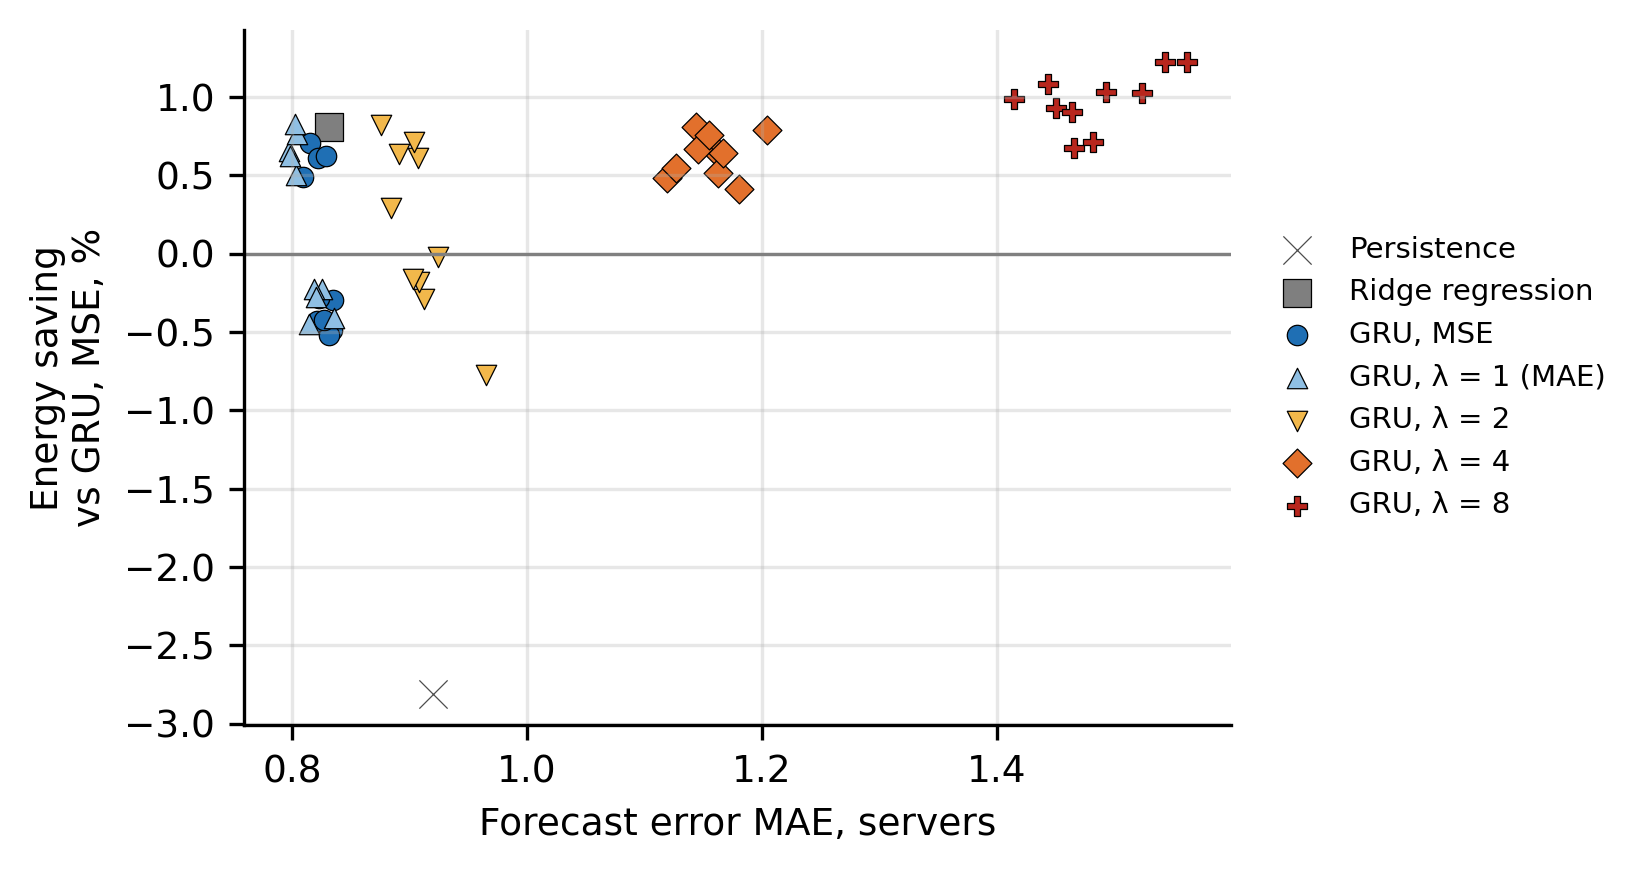

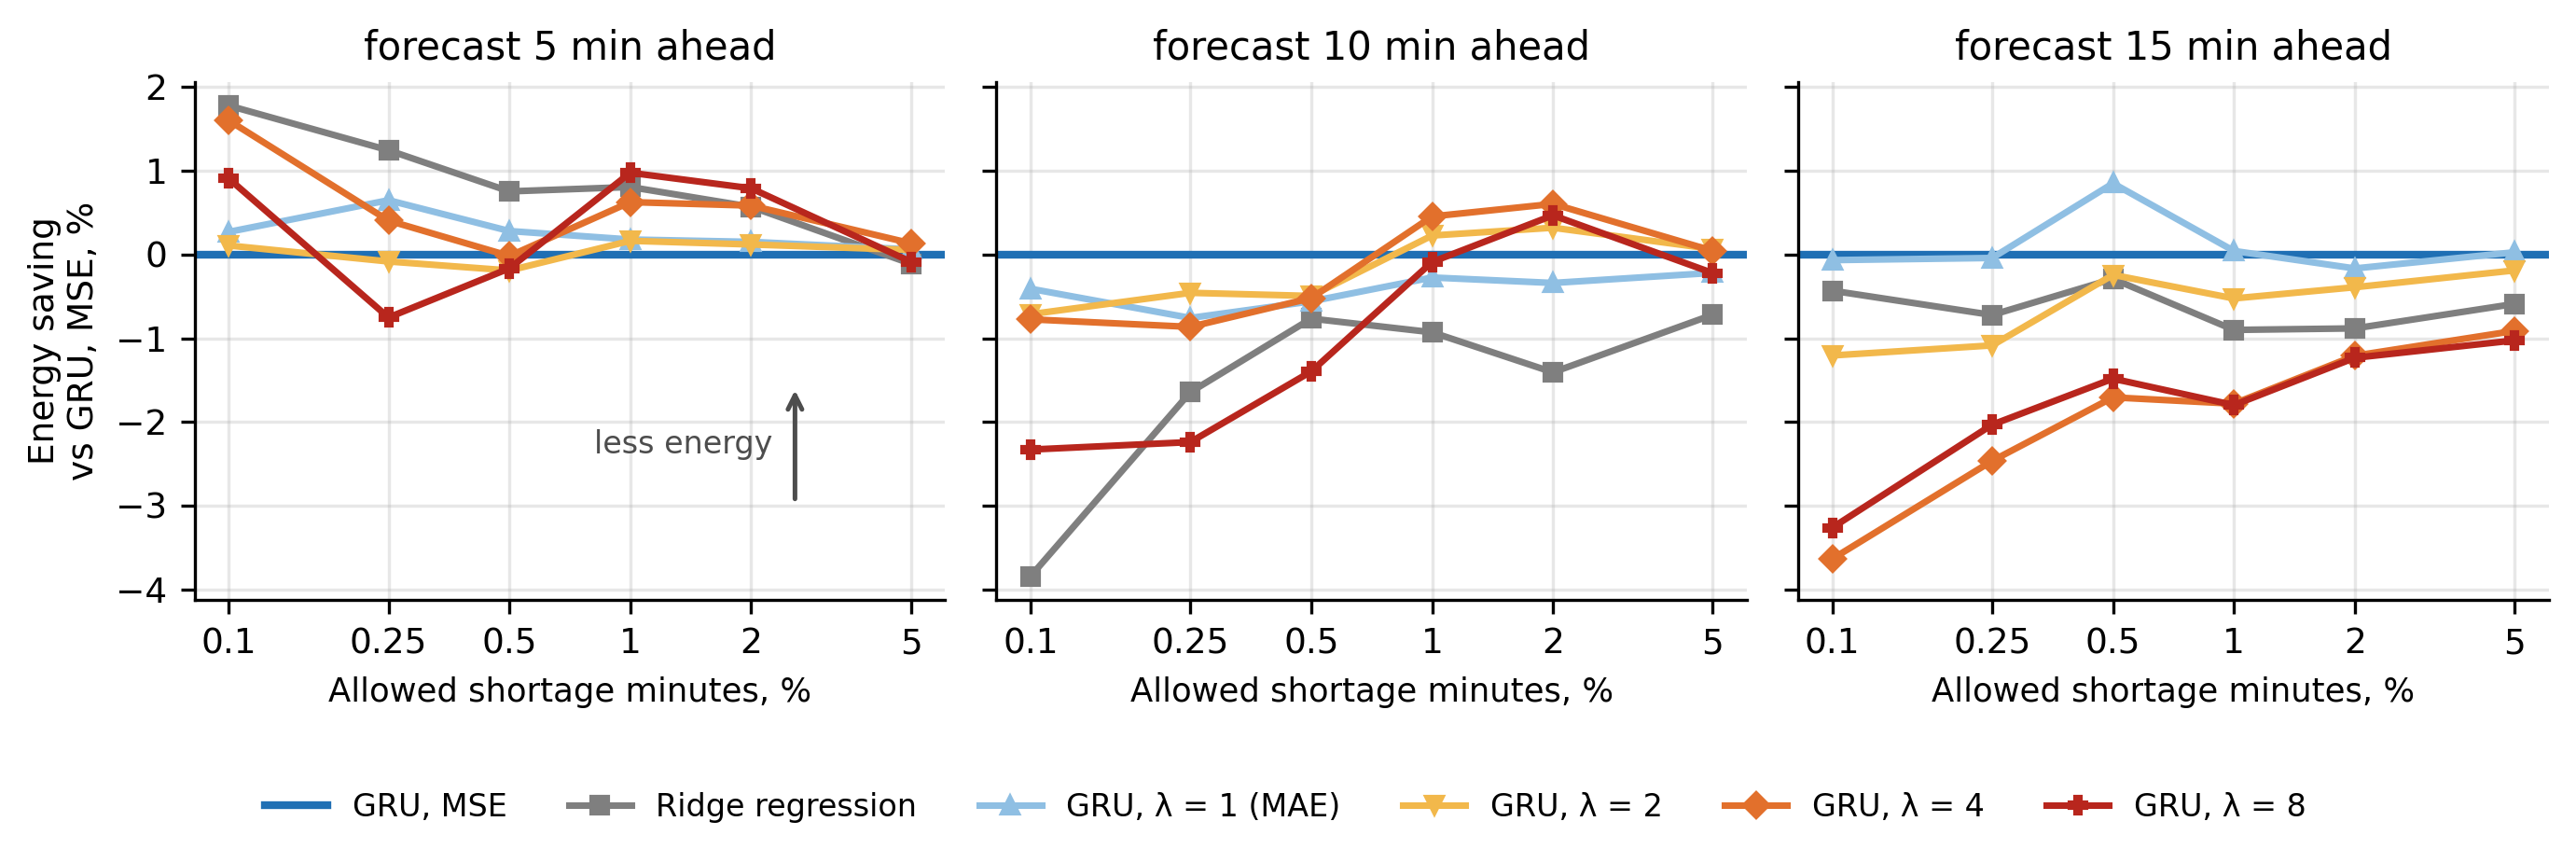

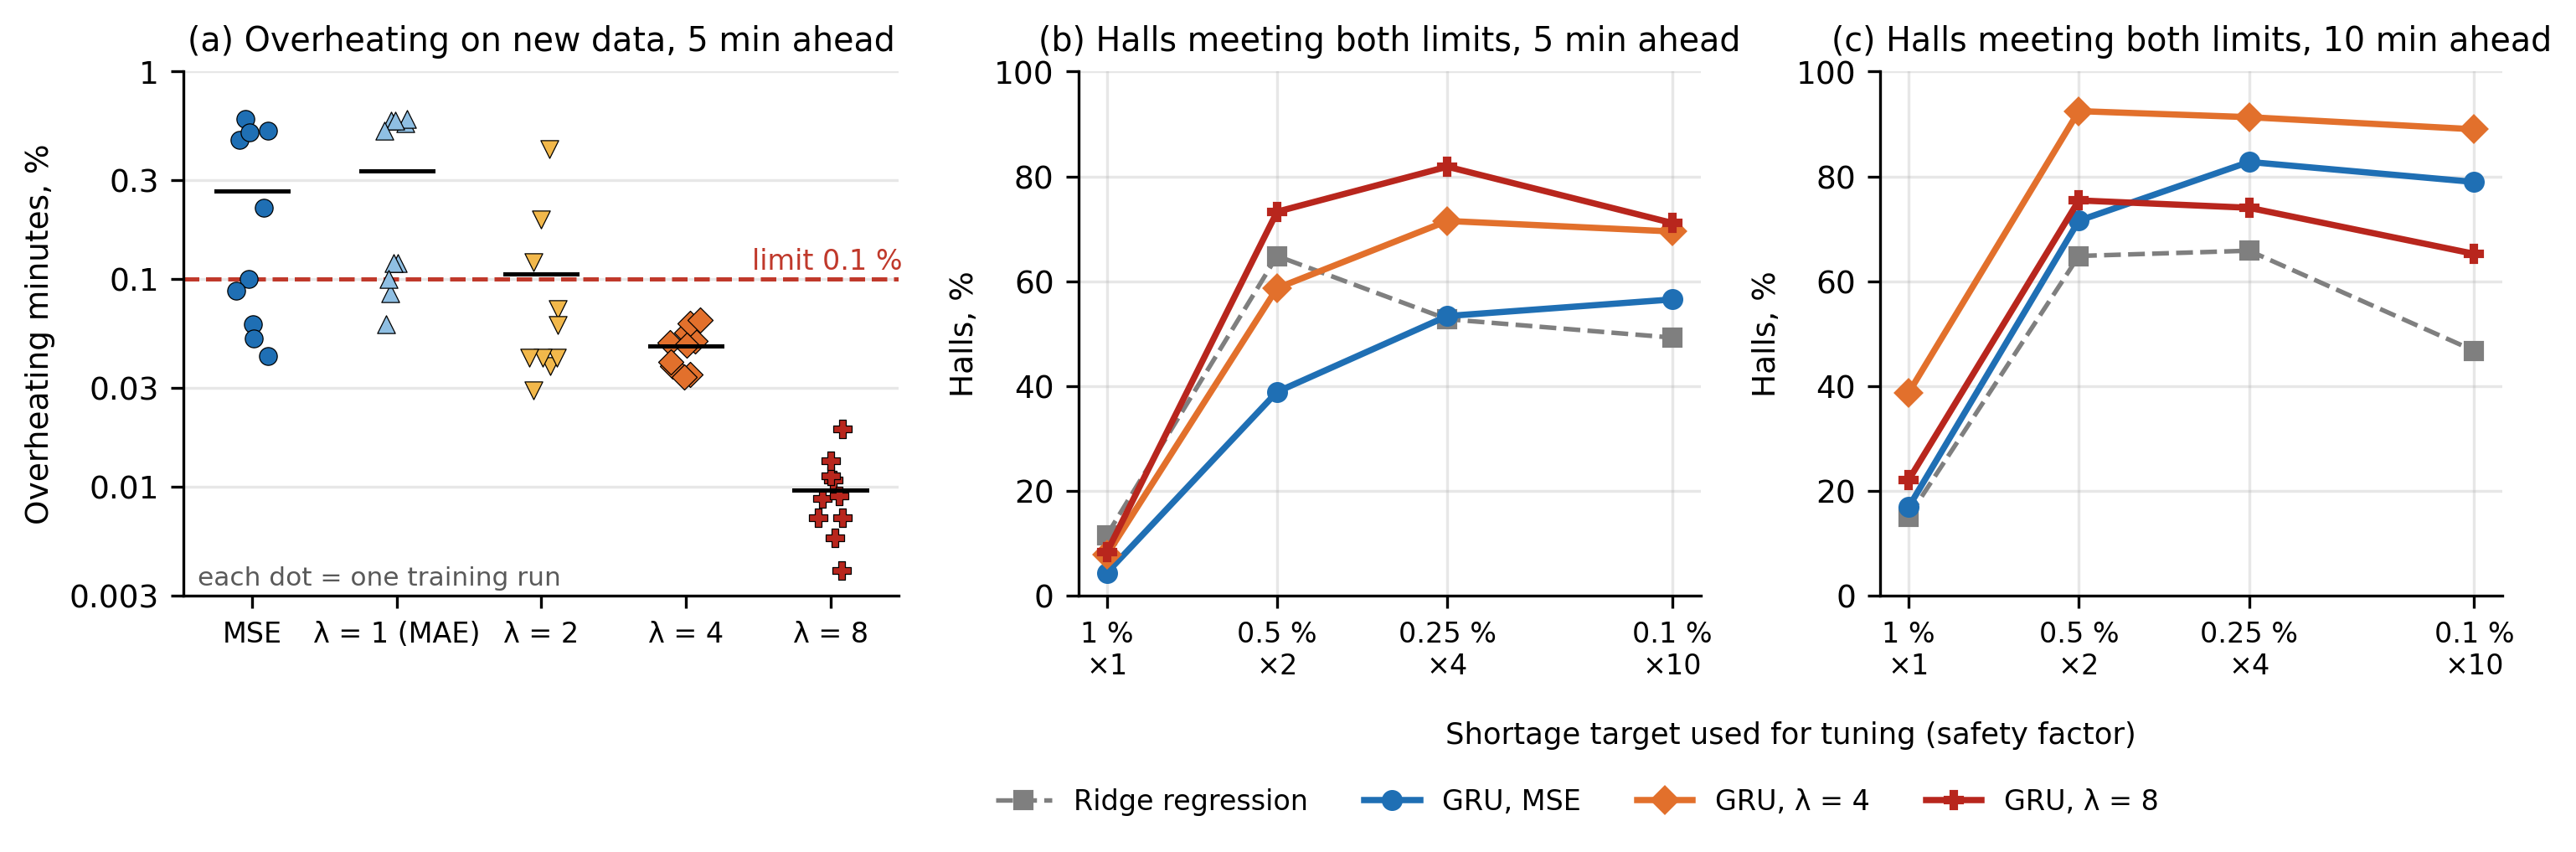

In [15]:
import glob
from IPython.display import Image, display
runs = " ".join(f"results/H{H}" for H in HORIZONS)
run(f"python scripts/04_report.py --runs {runs} --out results/report")
run(f"python scripts/05_figures.py --runs {runs} --report results/report --out results/figures")
for f in sorted(glob.glob("results/figures/*_en.png")):
    display(Image(filename=f, width=900))

## Zip the results
`forecasts.npz` files are big (hundreds of MB), so they are not added to the zip.

In [16]:
import zipfile
out = Path("/kaggle/working/results_dc_forecast_control.zip")
with zipfile.ZipFile(out, "w", zipfile.ZIP_DEFLATED) as z:
    for f in glob.glob("results/**/*", recursive=True):
        if os.path.isfile(f) and not f.endswith("forecasts.npz"):
            z.write(f)
print(out, f"{out.stat().st_size / 1e6:.1f} MB, total {(time.time() - T0) / 60:.0f} min")

/kaggle/working/results_dc_forecast_control.zip 14.8 MB, total 31 min
